In [1]:
from mt_rent_statement import *

### Load data

In [2]:
start='2026-10-01'
end='2026-10-30'
dfT=load_tenancies('all_tenancies.xls')
dfAll=load_data(start,end)
dfAll.head(3)

Reading file: C:\Work\Mat\property\data\property\checked\OCT2026_codedAndCategorised.xlsx


C:\Users\mathe\anaconda3\envs\Python36\lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat
2026-10-01,60-83-71 00558156,-315.00,REPAIRS_AND_MAINTENANCE,ALHHAMBRA ROAD M Tucker SC,NaN,NaN,ServiceCharge,NaN
2026-10-01,20-53-97 30728691,-620.94,Direct Debit,TOPAZ RE SIBERITE SIB00001/480016104 DD,F2146ALH,NaN,Mortgage,NaN
2026-10-01,20-74-09 60458872,-50.00,Standing Order,NATIONWIDE 0604/229172770 STO,NaN,NaN,RegularPayment,NaN


### Rent Statement

In [3]:
paidinadvancelist = []
inarrearslist = []
dfRs=get_rent_statement(dfAll, dfT, start, end, inarrearslist, paidinadvancelist)
dfRs=dfRs.round(0)
#dfRs.sort_values(by=['Net'], ascending=False).style.apply(custom_style, axis=1)
#dfRs.sort_values(by=['Bills'], ascending=True).style.apply(custom_style, axis=1)
#dfRs.style.apply(custom_style, axis=1)
num_cols = dfRs.select_dtypes(include=["number"]).columns
dfRs.style.format({c: "{:.0f}" for c in num_cols}).apply(custom_style, axis=1)

,Tenant,Agent,Received,Bills,Mortgage,Net,Status
Property,,,,,,,
321 London Rd,,,0,-222,0,-222,
Flat 1 - 321 London Rd,Ruksana Akter Chowdhury (09/08/2023),0,775,0,-392,383,Paid
Flat 2 - 321 London Rd,Mr Jake Bishop (16/03/2026),0,875,0,-376,499,Paid
Flat 3 - 321 London Rd,Harold Lingard-Kay & Stephen Cressdee (24/04/2026),0,1000,0,-315,685,Paid
Flat 4 - 321 London Rd,Chloe Freshney & Harry Aldingtons (31/01/2023),0,800,0,-392,408,Paid
169 Fawcett Rd,,,0,0,0,0,
Flat 1 - 169 Fawcett Rd,Miss Letisha Lowe (14/11/2025),0,825,-584,-353,-112,Paid
Flat 2 - 169 Fawcett Rd,Matthew Granil (31/07/2024),0,775,-96,-313,366,Paid
Flat 3 - 169 Fawcett Rd,,,0,149,-378,-229,Empty


Notes:
- 

Remarks:
- each 0.25% increase in rates causes an increase in costs of £750 - ideally we need rates back at 4.5% to pay £22500 p/m
- find out what happens when a business loans money to another and it is not repaid - ask Chatgpt
- things should improve in March - by then hopefully empties rented, paid in advance start to pay again in March


### Income/Expenditure per Property

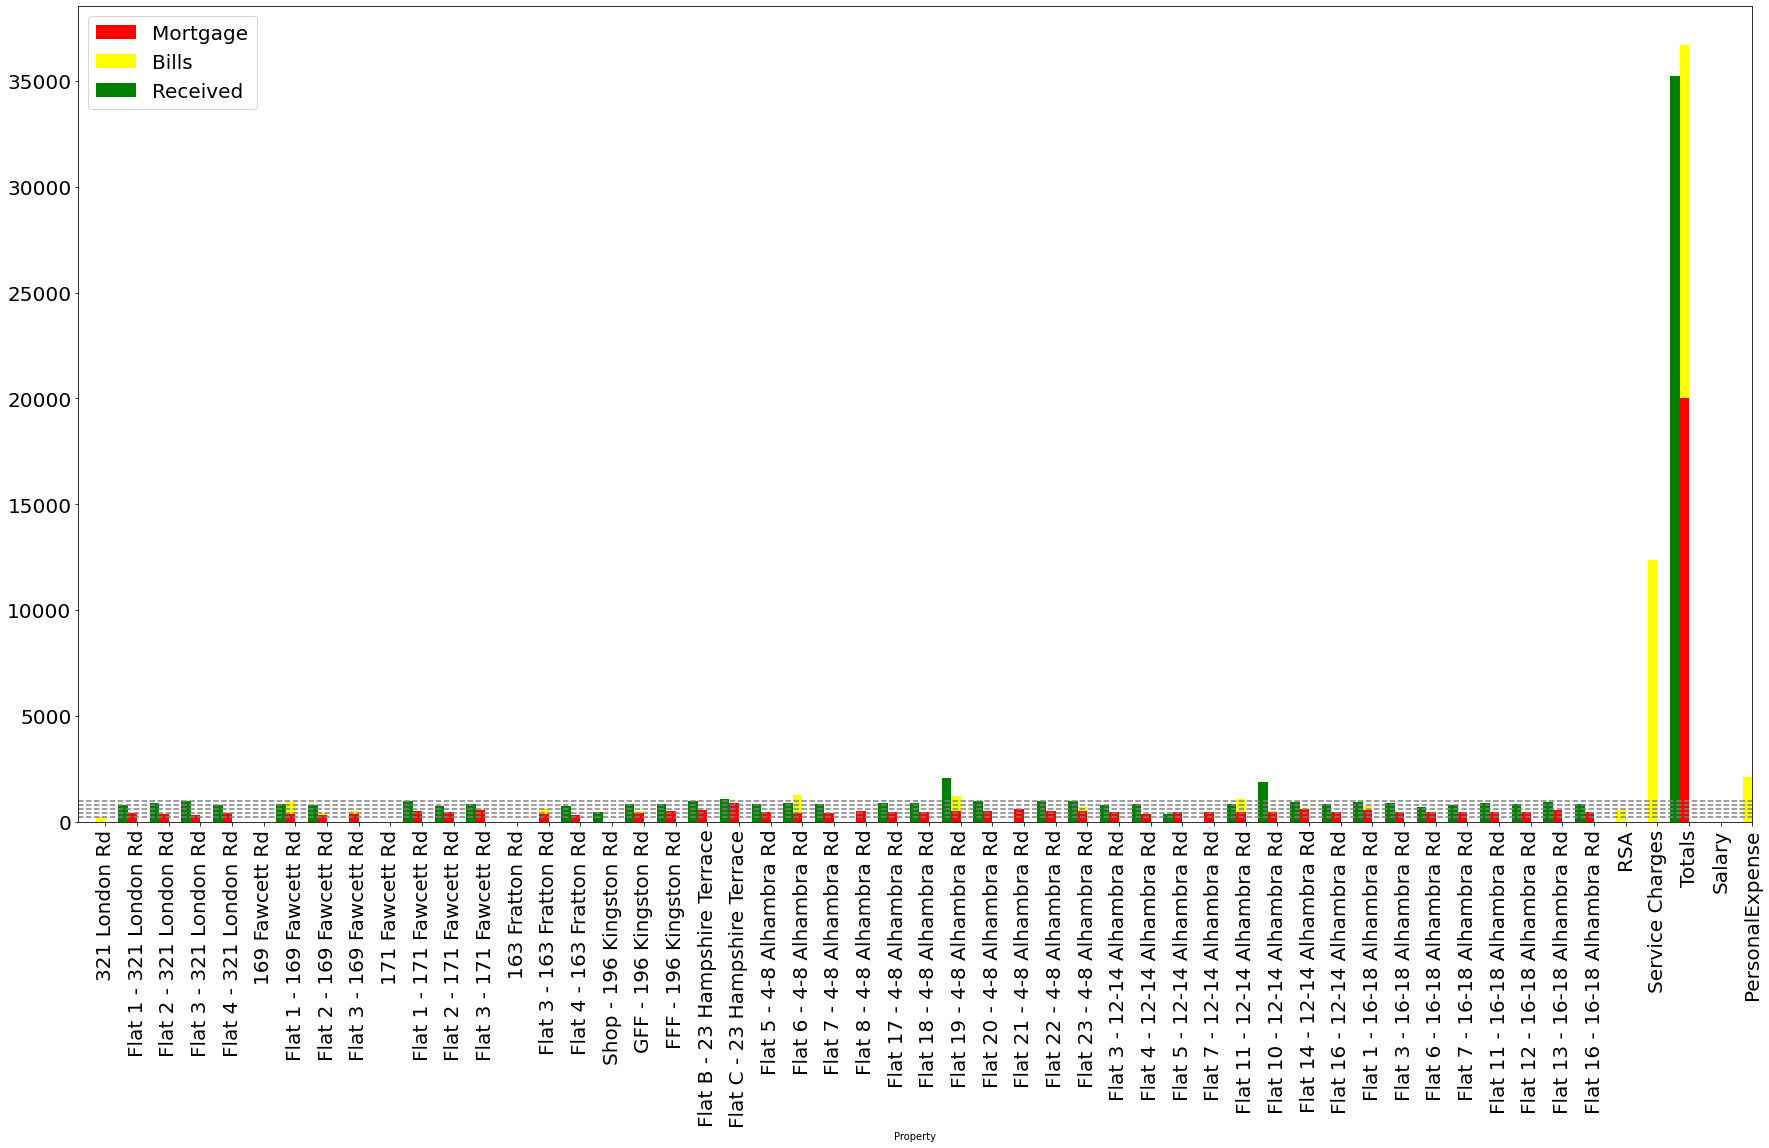

In [4]:
plot_income_expenditure_per_property(dfRs[:-1])

### Net Income Per Property

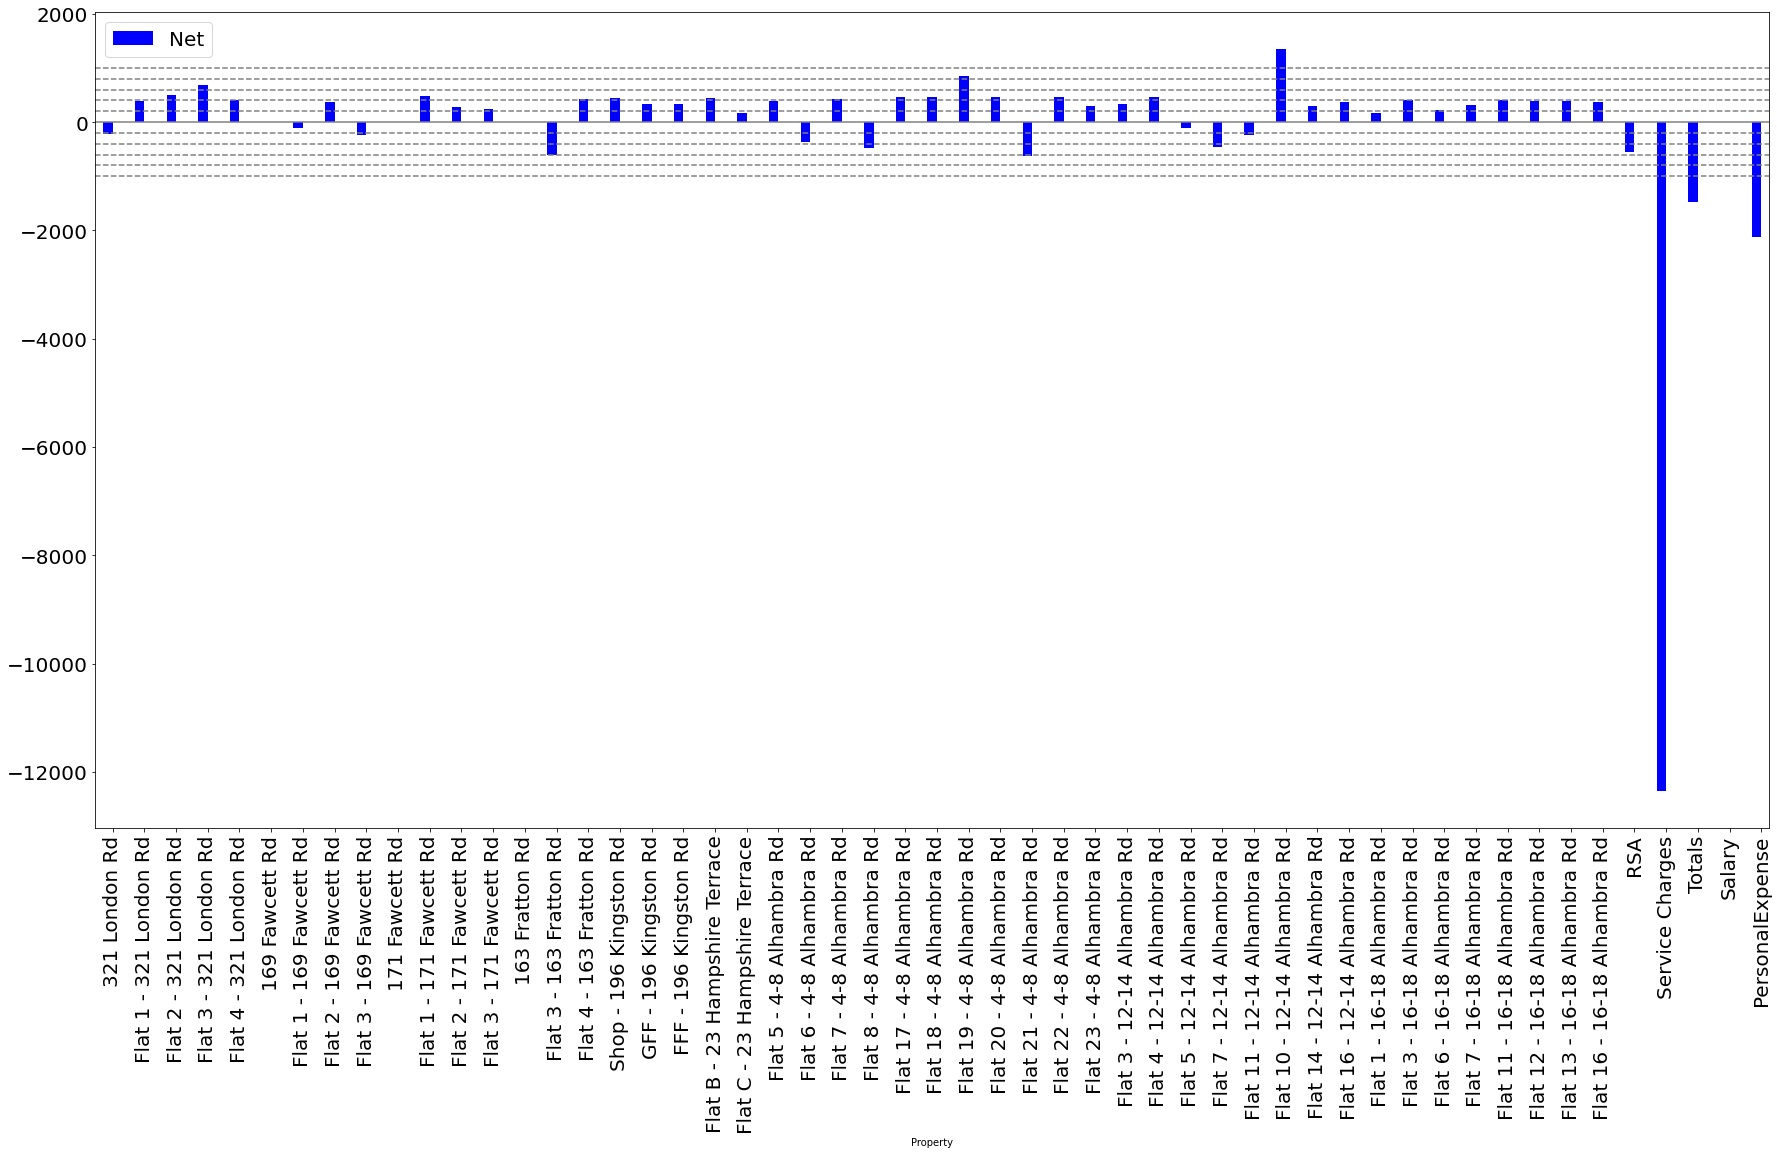

In [5]:
plot_net_income(dfRs[:-1])

### Accounts Check
Check Drawings against expenses

In [6]:
dfAll[(dfAll.Cat=='RegularPayment')|(dfAll.Cat=='PersonalExpense')|(dfAll.Cat=='Hilltop')|(dfAll.Cat=='HMRCDD')|(dfAll.Cat=='Drawings')|(dfAll.Cat=='SchoolFee')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
Hilltop,-300.00,0.0
PersonalExpense,-3470.45,0.0
RegularPayment,-1243.52,0.0
SchoolFee,-3488.73,0.0


In [7]:
dfAll.groupby(['Account','Cat']).sum().style.apply(custom_style_accounts_cat, axis=1)

#### Mortgage check
Check mortgages refunded from business account

In [8]:
dfMtg=dfAll[((dfAll.Cat=='Mortgage')|(dfAll.Cat=='MortgageRefund'))&(dfAll.Account!='60-83-71 00558156')].groupby(['Account','Cat']).Amount.sum()
dfMtg=dfMtg.reset_index().pivot('Account','Cat')
dfMtg.columns=dfMtg.columns.get_level_values(1)
if('MortgageRefund' not in dfMtg.columns):
    dfMtg['MortgageRefund']=0
dfMtg['Diff']=dfMtg.Mortgage + dfMtg.MortgageRefund
dfMtg

Cat,Mortgage,MortgageRefund,Diff
Account,,,
20-53-97 30728691,-20030.16,0,-20030.16


In [9]:
dfMtg['Diff'].sum()

-20030.160000000007

#### Rent check
Rents going to wrong account

In [10]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat


In [11]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='OurRent')].groupby(['Cat']).sum()

,Amount,Description
Cat,,


#### Property expense check
Property expenses and service charges taken from 3072 or 6045

In [12]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat
2026-10-05,20-74-09 60458872,-14.66,Card Purchase,AMAZON UK* NK2WR5A ON 03 OCT BCC,RSA,NaN,PropertyExpense,Amazon
2026-10-06,20-74-09 60458872,-9.99,Card Purchase,AMAZON* NK08P7DT4 ON 05 OCT BCC,RSA,NaN,PropertyExpense,Amazon
2026-10-07,20-74-09 60458872,-7.58,Card Purchase,AMAZON* NK9ER2YO4 ON 06 OCT BCC,RSA,NaN,PropertyExpense,Amazon
2026-10-08,20-74-09 60458872,-15.99,Card Purchase,AMAZON* BT45S7AW4 ON 08 OCT BCC,RSA,NaN,PropertyExpense,Amazon
2026-10-14,20-74-09 40406538,-32.98,Card Purchase,AMAZON* B80B99AW4 ON 14 OCT BCC,RSA,NaN,PropertyExpense,Amazon
2026-10-20,20-74-09 60458872,-9.54,Card Purchase,AMAZON UK* B04MU8E ON 20 OCT BCC,RSA,NaN,PropertyExpense,Amazon
2026-10-20,20-74-09 60458872,-6.99,Card Purchase,AMAZON* B08ZO5ES4 ON 20 OCT BCC,RSA,NaN,PropertyExpense,Amazon
2026-10-23,20-74-09 60458872,258.60,Counter Credit,3 169 FAWCETT ROAD SEQUENCE UK LIMITE BG,F3169FAW,NaN,PropertyExpense,NaN


In [13]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='PropertyExpense')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
PropertyExpense,160.87,0.0


In [14]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')]

,Account,Amount,Subcategory,Memo,Property,Description,Cat,Subcat


In [15]:
dfAll.loc[(dfAll.Account!='60-83-71 00558156')&(dfAll.Cat=='ServiceCharge')].groupby(['Cat']).sum()

,Amount,Description
Cat,,
